Qui-est-ce

In [ ]:
from google.colab import files
import pandas as pd

# Demander à l'utilisateur de télécharger le fichier CSV
uploaded = files.upload()

# Lire le fichier CSV dans un DataFrame
df = pd.read_csv(next(iter(uploaded)))

# Afficher le contenu du DataFrame
print(df)


Saving qui_est_ce_data.csv to qui_est_ce_data (5).csv
        Nom Sexe CouleurDeCheveux Lunette AgeCategorie Chapeau Moustache  \
0      Alex    M             Brun     Non       Adulte     Non       Oui   
1    Alfred    M             Roux     Non       Adulte     Non       Oui   
2     Anita    F            Blond     Non       Enfant     Non       Non   
3      Anne    F             Brun     Non       Adulte     Non       Non   
4   Bernard    M          Chatain     Non       Adulte     Oui       Non   
5     Susan    F             Gris     Oui       Adulte     Non       Non   
6     Peter    M             Gris     Non       Adulte     Non       Non   
7      Bill    M             Roux     Non       Adulte     Non       Non   
8     Maria    M          Chatain     Non       Adulte     Oui       Non   
9      Eric    M            Blond     Non       Adulte     Oui       Non   
10    Frans    M             Roux     Non       Adulte     Non       Non   
11  Charles    M            Blond 

In [ ]:
X = df.drop(columns=["Nom"])


In [ ]:
from sklearn import preprocessing
le_encod = preprocessing.LabelEncoder()
X["Sexe"] = le_encod.fit_transform(X["Sexe"])
X["Lunette"] = le_encod.fit_transform(X["Lunette"])
X["AgeCategorie"] = le_encod.fit_transform(X["AgeCategorie"])
X["Chapeau"] = le_encod.fit_transform(X["Chapeau"])
X["Moustache"] = le_encod.fit_transform(X["Moustache"])
X["Barbe"] = le_encod.fit_transform(X["Barbe"])
X["Calvitie"] = le_encod.fit_transform(X["Calvitie"])
X["CheveuxLong"] = le_encod.fit_transform(X["CheveuxLong"])
X

,Sexe,CouleurDeCheveux,Lunette,AgeCategorie,Chapeau,Moustache,Barbe,Calvitie,CheveuxLong
0,1,Brun,0,0,0,1,0,0,0
1,1,Roux,0,0,0,1,0,0,1
2,0,Blond,0,1,0,0,0,0,1
3,0,Brun,0,0,0,0,0,0,0
4,1,Chatain,0,0,1,0,0,0,0
5,0,Gris,1,0,0,0,0,0,1
6,1,Gris,0,0,0,0,0,0,0
7,1,Roux,0,0,0,0,1,1,0
8,1,Chatain,0,0,1,0,0,0,1
9,1,Blond,0,0,1,0,0,0,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Create a OneHotEncoder
encoder = OneHotEncoder(sparse=False)

# Fit and transform the "CouleurDeCheveux" column
encoded_columns = encoder.fit_transform(X[["CouleurDeCheveux"]])

# Create a DataFrame with the one-hot encoded columns
encoded_df = pd.DataFrame(encoded_columns, columns=encoder.get_feature_names_out(["CouleurDeCheveux"]))

print(encoded_columns)

[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]


/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [ ]:
# Drop the original "CouleurDeCheveux" column from X
X.drop(columns=["CouleurDeCheveux"], inplace=True)
X

,Sexe,Lunette,AgeCategorie,Chapeau,Moustache,Barbe,Calvitie,CheveuxLong
0,1,0,0,0,1,0,0,0
1,1,0,0,0,1,0,0,1
2,0,0,1,0,0,0,0,1
3,0,0,0,0,0,0,0,0
4,1,0,0,1,0,0,0,0
5,0,1,0,0,0,0,0,1
6,1,0,0,0,0,0,0,0
7,1,0,0,0,0,1,1,0
8,1,0,0,1,0,0,0,1
9,1,0,0,1,0,0,0,0


In [ ]:
# Concatenate the one-hot encoded DataFrame with X
X = pd.concat([X, encoded_df], axis=1)

In [ ]:
X

,Sexe,Lunette,AgeCategorie,Chapeau,Moustache,Barbe,Calvitie,CheveuxLong,CouleurDeCheveux_Blond,CouleurDeCheveux_Brun,CouleurDeCheveux_Chatain,CouleurDeCheveux_Gris,CouleurDeCheveux_Roux
0,1,0,0,0,1,0,0,0,0.0,1.0,0.0,0.0,0.0
1,1,0,0,0,1,0,0,1,0.0,0.0,0.0,0.0,1.0
2,0,0,1,0,0,0,0,1,1.0,0.0,0.0,0.0,0.0
3,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0
4,1,0,0,1,0,0,0,0,0.0,0.0,1.0,0.0,0.0
5,0,1,0,0,0,0,0,1,0.0,0.0,0.0,1.0,0.0
6,1,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0,0.0
7,1,0,0,0,0,1,1,0,0.0,0.0,0.0,0.0,1.0
8,1,0,0,1,0,0,0,1,0.0,0.0,1.0,0.0,0.0
9,1,0,0,1,0,0,0,0,1.0,0.0,0.0,0.0,0.0


In [ ]:
X.index = df['Nom']
X

,Sexe,Lunette,AgeCategorie,Chapeau,Moustache,Barbe,Calvitie,CheveuxLong,CouleurDeCheveux_Blond,CouleurDeCheveux_Brun,CouleurDeCheveux_Chatain,CouleurDeCheveux_Gris,CouleurDeCheveux_Roux
Nom,,,,,,,,,,,,,
Alex,1,0,0,0,1,0,0,0,0.0,1.0,0.0,0.0,0.0
Alfred,1,0,0,0,1,0,0,1,0.0,0.0,0.0,0.0,1.0
Anita,0,0,1,0,0,0,0,1,1.0,0.0,0.0,0.0,0.0
Anne,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0
Bernard,1,0,0,1,0,0,0,0,0.0,0.0,1.0,0.0,0.0
Susan,0,1,0,0,0,0,0,1,0.0,0.0,0.0,1.0,0.0
Peter,1,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0,0.0
Bill,1,0,0,0,0,1,1,0,0.0,0.0,0.0,0.0,1.0
Maria,1,0,0,1,0,0,0,1,0.0,0.0,1.0,0.0,0.0


In [ ]:
y = df["Nom"]
y

0        Alex
1      Alfred
2       Anita
3        Anne
4     Bernard
5       Susan
6       Peter
7        Bill
8       Maria
9        Eric
10      Frans
11    Charles
12     Herman
13    Georges
14     Claire
15        Max
16       Paul
17        Joe
18      David
19    Richard
20     Robert
21        Sam
22        Tom
23     Philip
Name: Nom, dtype: object

In [ ]:
from sklearn.tree import DecisionTreeClassifier

quiEstCeTree = DecisionTreeClassifier(criterion ='entropy')
quiEstCeTree  # it shows the default parameters

quiEstCeTree.fit(X,y)


DecisionTreeClassifier(criterion='entropy')

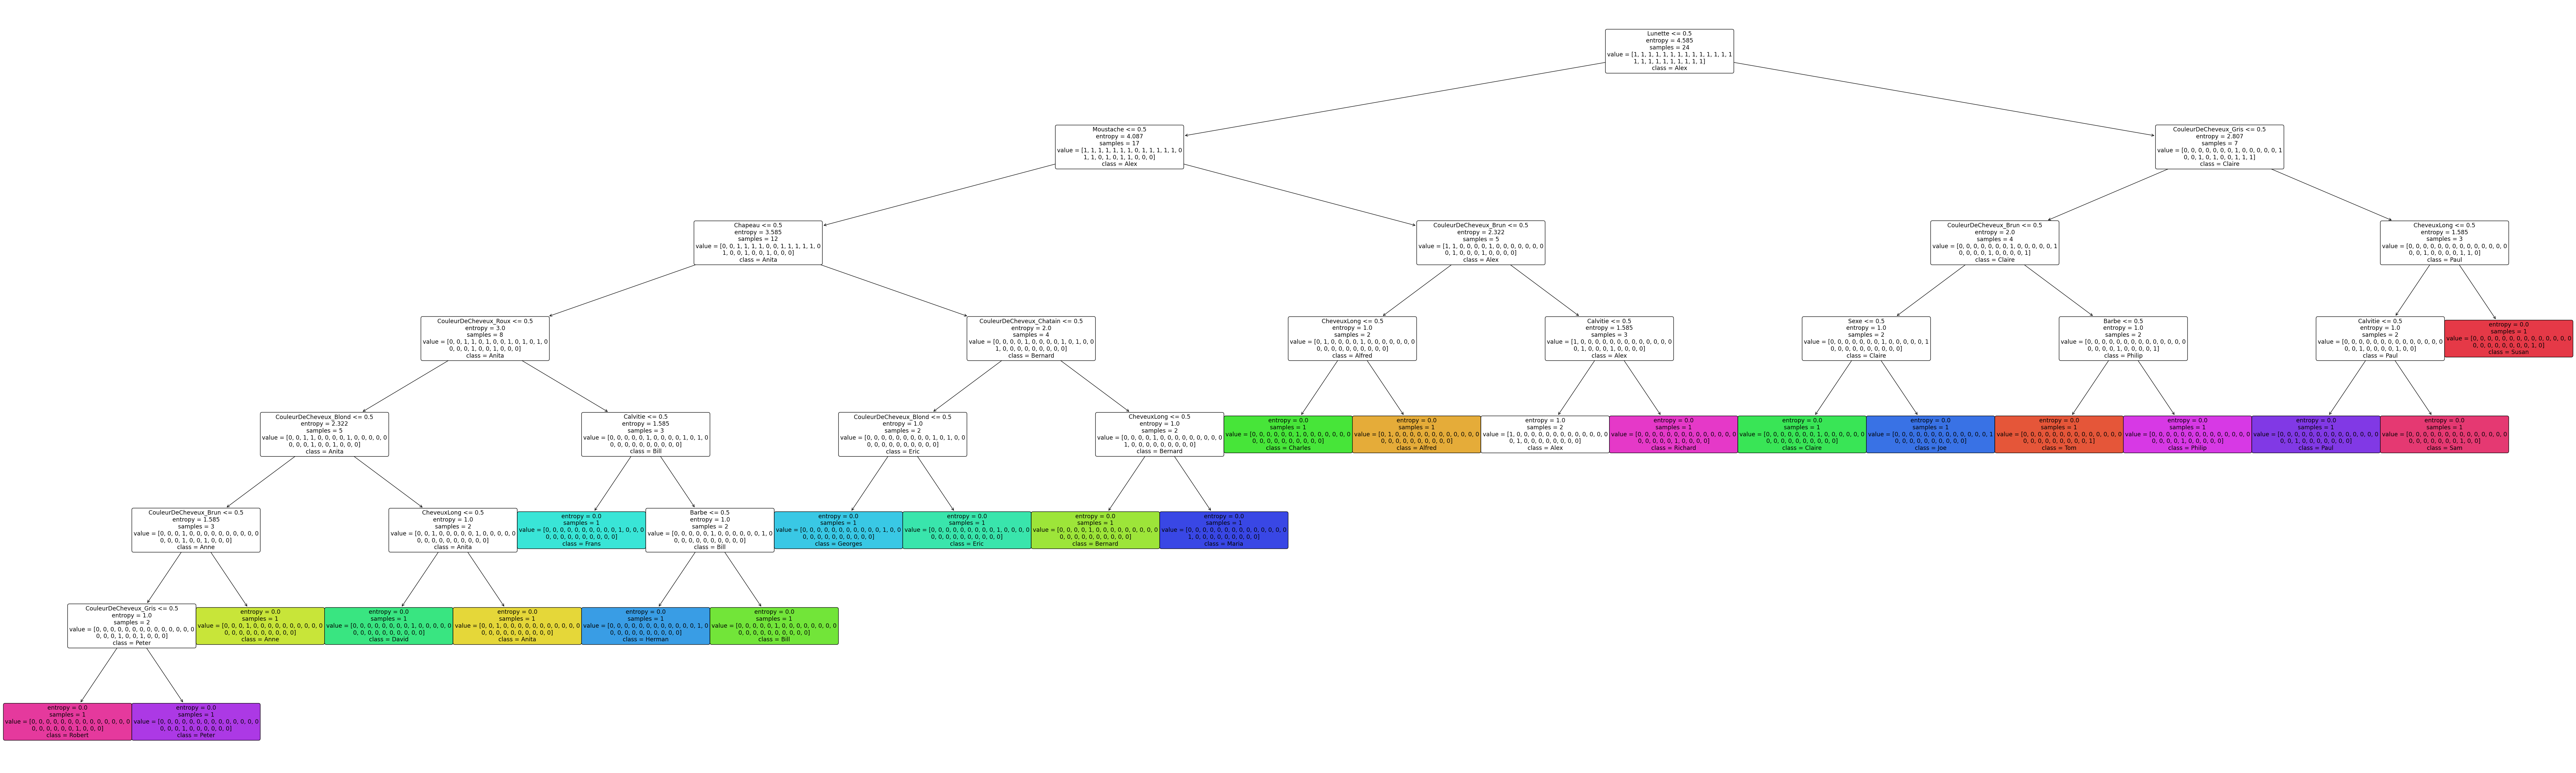

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Plot the decision tree with labels
plt.figure(figsize=(100, 30))
plot_tree(quiEstCeTree,feature_names=X.columns,class_names=quiEstCeTree.classes_,rounded=True,filled=True)
plt.show()

In [ ]:
from sklearn.tree import export_graphviz
export_graphviz(quiEstCeTree,out_file="quiEstCeTree.dot",feature_names=X.columns,class_names=quiEstCeTree.classes_,rounded=True,filled=True)

In [ ]:
# $ dot -Tpng quiEstCeTree.dot -o quiEstCeTree.png

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text
# Print the decision tree as text
tree_rules = export_text(quiEstCeTree, feature_names=list(X.columns))
print(tree_rules)

|--- Lunette <= 0.50
|   |--- Moustache <= 0.50
|   |   |--- Chapeau <= 0.50
|   |   |   |--- CouleurDeCheveux_Roux <= 0.50
|   |   |   |   |--- CouleurDeCheveux_Blond <= 0.50
|   |   |   |   |   |--- CouleurDeCheveux_Brun <= 0.50
|   |   |   |   |   |   |--- CouleurDeCheveux_Gris <= 0.50
|   |   |   |   |   |   |   |--- class: Robert
|   |   |   |   |   |   |--- CouleurDeCheveux_Gris >  0.50
|   |   |   |   |   |   |   |--- class: Peter
|   |   |   |   |   |--- CouleurDeCheveux_Brun >  0.50
|   |   |   |   |   |   |--- class: Anne
|   |   |   |   |--- CouleurDeCheveux_Blond >  0.50
|   |   |   |   |   |--- CheveuxLong <= 0.50
|   |   |   |   |   |   |--- class: David
|   |   |   |   |   |--- CheveuxLong >  0.50
|   |   |   |   |   |   |--- class: Anita
|   |   |   |--- CouleurDeCheveux_Roux >  0.50
|   |   |   |   |--- Calvitie <= 0.50
|   |   |   |   |   |--- class: Frans
|   |   |   |   |--- Calvitie >  0.50
|   |   |   |   |   |--- Barbe <= 0.50
|   |   |   |   |   |   |--- class: 

Arbre pour la regression

In [ ]:
import sklearn
import pandas as pd
from sklearn import datasets

In [ ]:
diabetes = datasets.load_diabetes()
columns = "age sex bmi map tc ldl hdl tch ltg glu".split()
x = pd.DataFrame(diabetes.data, columns=columns)
y = diabetes.target
x.head()

,age,sex,bmi,map,tc,ldl,hdl,tch,ltg,glu
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
y[0:5]

array([151.,  75., 141., 206., 135.])

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(353, 10) (353,)
(89, 10) (89,)


In [ ]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(max_depth=3)
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3)

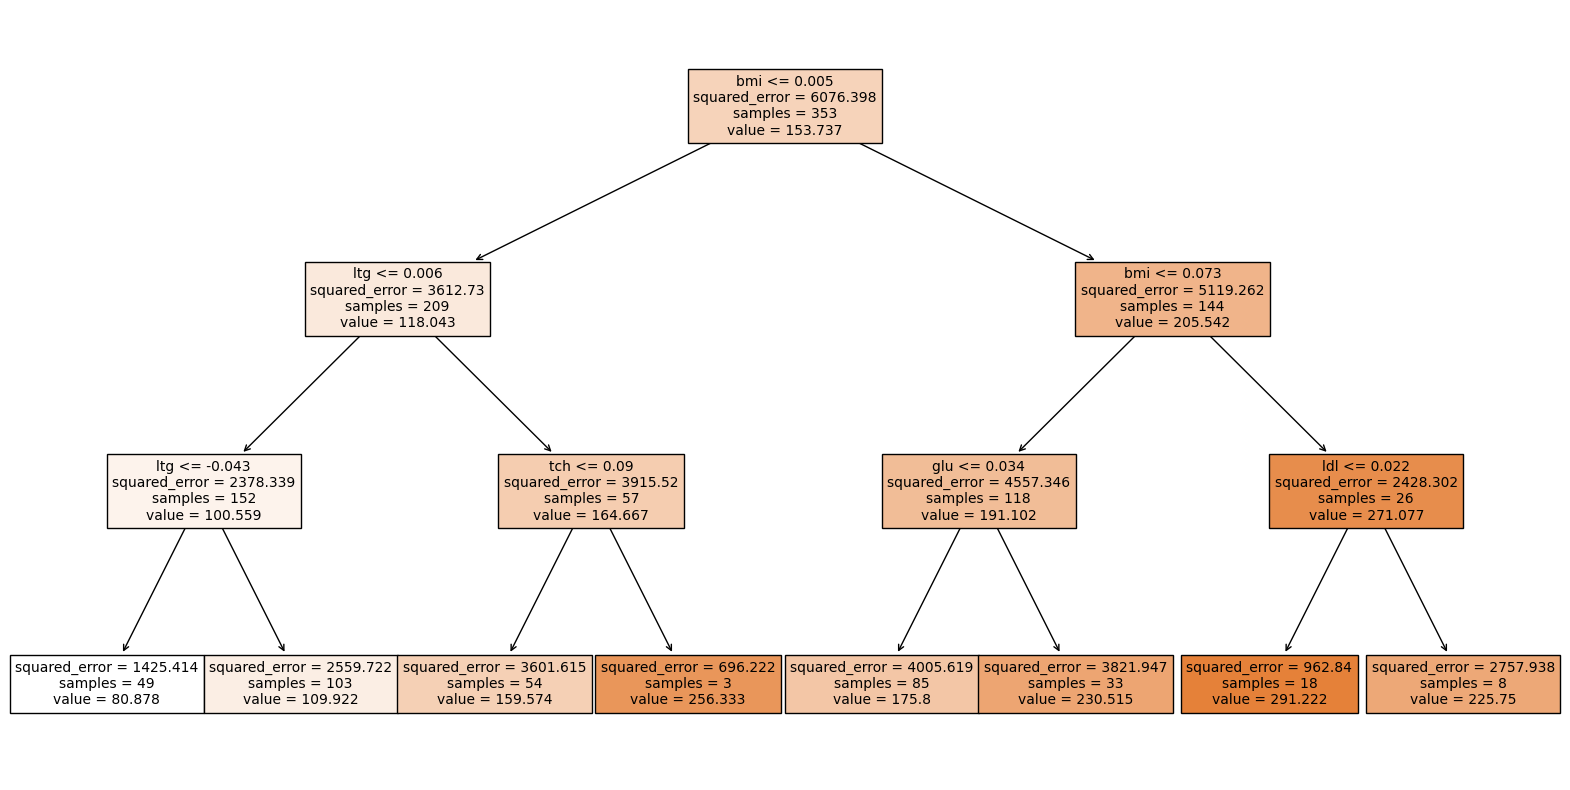

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Plot the decision tree with labels
plt.figure(figsize=(20, 10))
plot_tree(model, filled=True, feature_names=x.columns)
plt.show()

In [ ]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

In [ ]:
from sklearn.metrics import r2_score
print(r2_score(y_train, y_pred_train))
print(r2_score(y_test, y_pred_test))

0.5169770705085918
0.3294451571119206


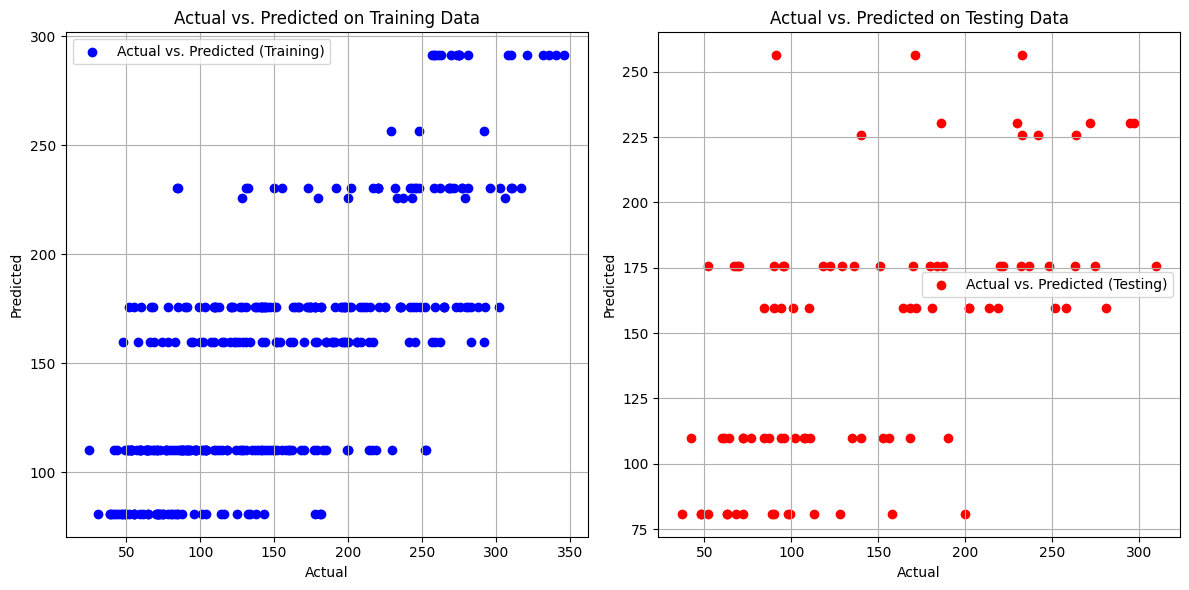

In [ ]:
import matplotlib.pyplot as plt

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot for training data
axes[0].scatter(y_train, y_pred_train, c='b', marker='o', label='Actual vs. Predicted (Training)')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Actual vs. Predicted on Training Data')
axes[0].legend(loc='best')
axes[0].grid(True)

# Plot for testing data
axes[1].scatter(y_test, y_pred_test, c='r', marker='o', label='Actual vs. Predicted (Testing)')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title('Actual vs. Predicted on Testing Data')
axes[1].legend(loc='best')
axes[1].grid(True)

# Adjust layout for better spacing
plt.tight_layout()

# Show the plots
plt.show()


Hypermaramètres

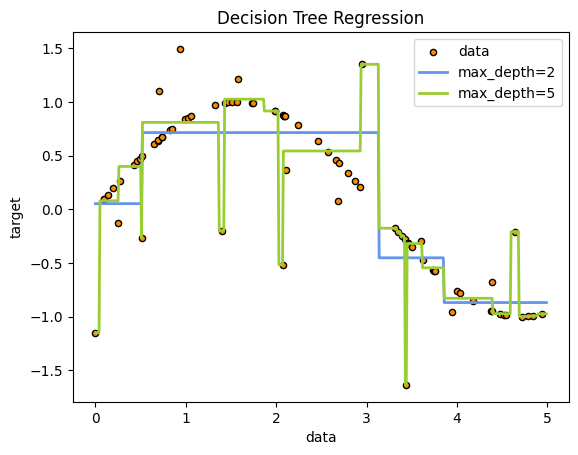

In [ ]:
# Import the necessary modules and libraries
import matplotlib.pyplot as plt
import numpy as np

from sklearn.tree import DecisionTreeRegressor

# Create a random dataset
rng = np.random.RandomState(1)
X = np.sort(5 * rng.rand(80, 1), axis=0)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(16))

# Fit regression model
regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

# Predict
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)

# Plot the results
plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.plot(X_test, y_2, color="yellowgreen", label="max_depth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()



Multi Output predictor
L'image est quantifiée en 256 niveaux de gris et stockée sous forme d'entiers non signés de 8 bits ; le chargeur les convertira en valeurs à virgule flottante sur l'intervalle [0, 1], qui sont plus faciles à utiliser pour de nombreux algorithmes.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


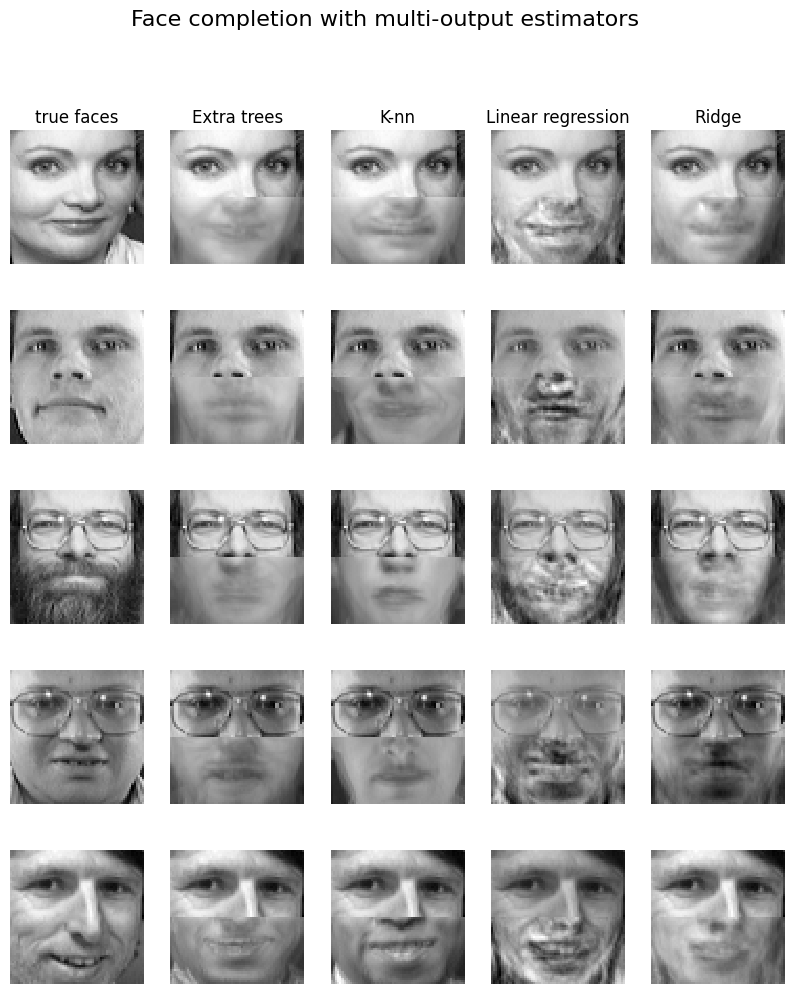

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import fetch_olivetti_faces
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.utils.validation import check_random_state

# Load the faces datasets
data, targets = fetch_olivetti_faces(return_X_y=True)

train = data[targets < 30]
test = data[targets >= 30]  # Test on independent people

# Test on a subset of people
n_faces = 5
rng = check_random_state(4)
face_ids = rng.randint(test.shape[0], size=(n_faces,))
test = test[face_ids, :]

n_pixels = data.shape[1]
# Upper half of the faces
X_train = train[:, : (n_pixels + 1) // 2]
# Lower half of the faces
y_train = train[:, n_pixels // 2 :]
X_test = test[:, : (n_pixels + 1) // 2]
y_test = test[:, n_pixels // 2 :]

# Fit estimators
ESTIMATORS = {
    "Extra trees": ExtraTreesRegressor(
        n_estimators=10, max_features=32, random_state=0
    ),
    "K-nn": KNeighborsRegressor(),
    "Linear regression": LinearRegression(),
    "Ridge": RidgeCV(),
}

y_test_predict = dict()
for name, estimator in ESTIMATORS.items():
    estimator.fit(X_train, y_train)
    y_test_predict[name] = estimator.predict(X_test)

# Plot the completed faces
image_shape = (64, 64)

n_cols = 1 + len(ESTIMATORS)
plt.figure(figsize=(2.0 * n_cols, 2.26 * n_faces))
plt.suptitle("Face completion with multi-output estimators", size=16)

for i in range(n_faces):
    true_face = np.hstack((X_test[i], y_test[i]))

    if i:
        sub = plt.subplot(n_faces, n_cols, i * n_cols + 1)
    else:
        sub = plt.subplot(n_faces, n_cols, i * n_cols + 1, title="true faces")

    sub.axis("off")
    sub.imshow(
        true_face.reshape(image_shape), cmap=plt.cm.gray, interpolation="nearest"
    )

    for j, est in enumerate(sorted(ESTIMATORS)):
        completed_face = np.hstack((X_test[i], y_test_predict[est][i]))

        if i:
            sub = plt.subplot(n_faces, n_cols, i * n_cols + 2 + j)

        else:
            sub = plt.subplot(n_faces, n_cols, i * n_cols + 2 + j, title=est)

        sub.axis("off")
        sub.imshow(
            completed_face.reshape(image_shape),
            cmap=plt.cm.gray,
            interpolation="nearest",
        )

plt.show()


array([0.47107437, 0.53305787, 0.57438016, ..., 0.6818182 , 0.71900827,
       0.74380165], dtype=float32)

CART sur le jeu de données Tennis

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving tennis.csv to tennis.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

tennis_data = pd.read_csv('tennis.csv',sep = ';')

df = pd.DataFrame(data = tennis_data)
df

,Jour,Prévisions,Température,Humidité,Vent,Jouer
0,1,Ensoleillé,Chaud,Élevée,Faible,Non
1,2,Ensoleillé,Chaud,Élevée,Fort,Non
2,3,Nuageux,Chaud,Élevée,Faible,Oui
3,4,Pluvieux,Moyen,Élevée,Faible,Oui
4,5,Pluvieux,Frais,Normale,Faible,Oui
5,6,Pluvieux,Frais,Normale,Fort,Non
6,7,Nuageux,Frais,Normale,Fort,Oui
7,8,Ensoleillé,Moyen,Élevée,Faible,Non
8,9,Ensoleillé,Frais,Normale,Faible,Oui
9,10,Pluvieux,Moyen,Normale,Faible,Oui


In [ ]:
df['Jouer'].value_counts()

Oui    9
Non    5
Name: Jouer, dtype: int64

In [ ]:
#Nombre de lignes / colonnes
df.shape

(14, 6)

In [ ]:
def log_base_k(x,k):
  return(np.log(x)/np.log(k))

In [ ]:
#exemple
log_base_k(9/14,2)

-0.6374299206152917

In [ ]:
log_base_k((5/14),2)

-1.4854268271702415

In [ ]:
E = -((9/14)*log_base_k((9/14),2) +  (5/14)*log_base_k((5/14),2)  )
E

0.9402859586706309

L'entropie à la racine est de 0.94

In [ ]:
#Avec scipy on retrouve la formule directement
from scipy.stats import entropy
entropy([9/14, 5/14], base=2)

0.940285958670631

Étude de Prévision avec toutes les combinaisons possibles

In [ ]:
#Soleil, Couvert + Pluie
print(df[df["Prévisions"] == 'Ensoleillé']['Jouer'].value_counts())
print("Entropy")
print(entropy([3/5, 2/5], base=2))

Non    3
Oui    2
Name: Jouer, dtype: int64
Entropy
0.9709505944546688


In [ ]:
print(df[df["Prévisions"].isin(['Nuageux','Pluvieux' ]) ]['Jouer'].value_counts())
print("Entropy")
print(entropy([7/9, 2/9], base=2))

Oui    7
Non    2
Name: Jouer, dtype: int64
Entropy
0.7642045065086203


In [ ]:
# Entropie finale avec
(5/14)*entropy([3/5, 2/5], base=2)+(9/14)*entropy([7/9, 2/9], base=2)

0.8380423950607805

In [ ]:
#On crée une fonction pour aller plus vite

def Entropy_conditional(mydf,liste_1 ,liste_2,Name_col, total):
    #nombre de ligne avant split
    print(total)
    valCount = mydf[mydf[Name_col].isin(liste_1)]['Jouer'].value_counts().rename_axis('unique_values').to_frame('counts')
    print(valCount)
    if(valCount.shape[0]==1):
        E1 = 0
    else:
        nRows =  sum(valCount["counts"])
        E1 = (nRows/total)*entropy([valCount.loc["Non"]/nRows, valCount.loc["Oui"]/nRows], base=2)

    valCount = mydf[mydf[Name_col].isin(liste_2) ]['Jouer'].value_counts().rename_axis('unique_values').to_frame('counts')
    print(valCount)
    if(valCount.shape[0]==1):
        E2 = 0
    else:
        nRows =  sum(valCount["counts"])
        E2 = (nRows/total)*entropy([valCount.loc["Non"]/nRows, valCount.loc["Oui"]/nRows], base=2)

    print("Entropie total")
    print(E1+E2)
    return(E1+E2)

In [ ]:
#Soleil, Couvert + Pluie
liste_1 = ['Ensoleillé']
liste_2 = ['Nuageux','Puivieux' ]
Name_col = 'Prévisions'

Entropy_conditional(df,liste_1 ,liste_2,Name_col ,df.shape[0])

14
               counts
unique_values        
Non                 3
Oui                 2
               counts
unique_values        
Oui                 4
Entropie total
[0.34676807]


array([0.34676807])

In [ ]:
# Couvert,Soleil  + Pluie
liste_1 = ['Nuageux']
liste_2 = ['Ensoleillé','Pluvieux' ]
Name_col = 'Prévisions'

Entropy_conditional(df,liste_1 ,liste_2,Name_col,total = df.shape[0] )

14
               counts
unique_values        
Oui                 4
               counts
unique_values        
Non                 5
Oui                 5
Entropie total
[0.71428571]


array([0.71428571])

In [ ]:
# Pluie + Couvert + Soleil
liste_1 = ['Pluvieux']
liste_2 = ['Ensoleillé','Nuageux' ]
Entropy_conditional(df,liste_1 ,liste_2,Name_col ,total = df.shape[0])

14
               counts
unique_values        
Oui                 3
Non                 2
               counts
unique_values        
Oui                 6
Non                 3
Entropie total
[0.93710111]


array([0.93710111])

Température

In [ ]:
print(Entropy_conditional(df,["Chaud"],["Moyen","Frais"],"Température", df.shape[0]))
print(Entropy_conditional(df,["Moyen"],["Chaud","Frais"],"Température", df.shape[0]))
print(Entropy_conditional(df,["Frais"],["Chaud","Moyen"],"Température", df.shape[0]))

14
               counts
unique_values        
Non                 2
Oui                 2
               counts
unique_values        
Oui                 7
Non                 3
Entropie total
[0.91520779]
[0.91520779]
14
               counts
unique_values        
Oui                 4
Non                 2
               counts
unique_values        
Oui                 5
Non                 3
Entropie total
[0.93894622]
[0.93894622]
14
               counts
unique_values        
Oui                 3
Non                 1
               counts
unique_values        
Oui                 6
Non                 4
Entropie total
[0.92532989]
[0.92532989]


Humidité

In [ ]:
#humidité
liste_1 = ["Élevée"]
liste_2 = ["Normale"]
Name_col = "Humidité"
Entropy_conditional(df,liste_1 ,liste_2,Name_col ,df.shape[0])

14
               counts
unique_values        
Non                 4
Oui                 3
               counts
unique_values        
Oui                 6
Non                 1
Entropie total
[0.78845046]


array([0.78845046])

Vent

In [ ]:
#vent ou non vent
liste_1 = ["Faible"]
liste_2 = ["Fort"]
Name_col = "Vent"
Entropy_conditional(df,liste_1 ,liste_2,Name_col ,df.shape[0])

14
               counts
unique_values        
Oui                 6
Non                 2
               counts
unique_values        
Non                 3
Oui                 3
Entropie total
[0.89215893]


array([0.89215893])

On fait le premier split sur 'prévision' avec d'un côté "Ensolleillé" et d'un côté "Nuageux ou Pluvieux"

In [ ]:
entropy([2/5, 3/5], base=2)

0.9709505944546688

In [ ]:
entropy([7/9, 2/9], base=2)

0.7642045065086203

Développement du fils de gauche

In [ ]:
df1 = df[df["Prévisions"] == 'Ensoleillé']

Température

In [ ]:
print(Entropy_conditional(df1,["Chaud"],["Moyen","Frais"],"Température", df1.shape[0]))
print(Entropy_conditional(df1,["Moyen"],["Chaud","Frais"],"Température", df1.shape[0]))
print(Entropy_conditional(df1,["Frais"],["Chaud","Moyen"],"Température", df1.shape[0]))

5
               counts
unique_values        
Non                 2
               counts
unique_values        
Oui                 2
Non                 1
Entropie total
[0.5509775]
[0.5509775]
5
               counts
unique_values        
Non                 1
Oui                 1
               counts
unique_values        
Non                 2
Oui                 1
Entropie total
[0.9509775]
[0.9509775]
5
               counts
unique_values        
Oui                 1
               counts
unique_values        
Non                 3
Oui                 1
Entropie total
[0.6490225]
[0.6490225]


Humidité

In [ ]:
#humidité
liste_1 = ["Élevée"]
liste_2 = ["Normale"]
Name_col = "Humidité"
Entropy_conditional(df1,liste_1 ,liste_2,Name_col ,df1.shape[0])

5
               counts
unique_values        
Non                 3
               counts
unique_values        
Oui                 2
Entropie total
0


0

On arrête le développement du fils de gauche car on une entropie

Développement du fils de droite

In [ ]:
df2 = df[df["Prévisions"].isin(['Nuageux','Pluvieux' ]) ]

Prévision

In [ ]:
#prévision
liste_1 = ["Nuageux"]
liste_2 = ["Pluvieux"]
Name_col = "Prévisions"
Entropy_conditional(df2,liste_1 ,liste_2,Name_col ,df2.shape[0])

9
               counts
unique_values        
Oui                 4
               counts
unique_values        
Oui                 3
Non                 2
Entropie total
[0.539417]


array([0.539417])

Température

In [ ]:
print(Entropy_conditional(df2,["Chaud"],["Moyen","Frais"],"Température", df2.shape[0]))
print(Entropy_conditional(df2,["Moyen"],["Chaud","Frais"],"Température", df2.shape[0]))
print(Entropy_conditional(df2,["Frais"],["Chaud","Moyen"],"Température", df2.shape[0]))

9
               counts
unique_values        
Oui                 2
               counts
unique_values        
Oui                 5
Non                 2
Entropie total
[0.671316]
[0.671316]
9
               counts
unique_values        
Oui                 3
Non                 1
               counts
unique_values        
Oui                 4
Non                 1
Entropie total
[0.76163922]
[0.76163922]
9
               counts
unique_values        
Oui                 2
Non                 1
               counts
unique_values        
Oui                 5
Non                 1
Entropie total
[0.73944689]
[0.73944689]


Humidité

In [ ]:
#humidité
liste_1 = ["Élevée"]
liste_2 = ["Normale"]
Name_col = "Humidité"
Entropy_conditional(df2,liste_1 ,liste_2,Name_col ,df2.shape[0])

9
               counts
unique_values        
Oui                 3
Non                 1
               counts
unique_values        
Oui                 4
Non                 1
Entropie total
[0.76163922]


array([0.76163922])

Vent

In [ ]:
#vent ou non vent
liste_1 = ["Faible"]
liste_2 = ["Fort"]
Name_col = "Vent"
Entropy_conditional(df2,liste_1 ,liste_2,Name_col ,df2.shape[0])

9
               counts
unique_values        
Oui                 5
               counts
unique_values        
Non                 2
Oui                 2
Entropie total
[0.44444444]


array([0.44444444])

Développement du fils de droite

In [ ]:
df3 = df2[df2["Vent"]== "Fort" ]

In [ ]:
#prévision
liste_1 = ["Nuageux"]
liste_2 = ["Pluvieux"]
Name_col = "Prévisions"
Entropy_conditional(df3,liste_1 ,liste_2,Name_col ,df3.shape[0])

4
               counts
unique_values        
Oui                 2
               counts
unique_values        
Non                 2
Entropie total
0


0